# MCMC-PESP: Proof of Concept - Triangle Network

This notebook demonstrates the MCMC algorithm for the Periodic Event Scheduling Problem (PESP) on a simple triangle network.

## Contents
1. Project Status Overview
2. Triangle Network Setup
3. MCMC Configuration
4. Precompute MCMC History
5. Interactive Step-by-Step Visualization
6. Results Analysis

In [1]:
# Setup
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Enable interactive matplotlib
%matplotlib inline

# Import MCMC-PESP modules
from src.core.schedule import Schedule
from src.core.transfers import DEFAULT_TRANSFER_PARAMS
from src.cost.transfer_cost import TransferCost
from src.io.synthetic import TriangleNetwork
from src.mcmc.proposals.single_line import SingleLineShift
from src.visualization import (
    NetworkPlotter,
    MCMCRecorder,
    ProjectStatus,
    create_mcmc_player,
)

print("MCMC-PESP modules loaded successfully!")

MCMC-PESP modules loaded successfully!


---
## 1. Project Status Overview

Current implementation status of all modules:

In [2]:
# Display project status
status = ProjectStatus()
status.display_status()

---
## 2. Triangle Network Setup

The Triangle network is a simple test case with:
- 3 locations: A, B, C
- 3 lines: L1 (A→B), L2 (B→C), L3 (A→C)
- 1 transfer: at B from L1 to L2

The optimal solution has all transfers at the ideal waiting time (8 minutes).

In [3]:
# Create triangle network
builder = TriangleNetwork(
    period=60,         # 60-minute period
    travel_time=15,    # 15 min between stations
    dwell_time=2,      # 2 min dwell at each station
    walk_time=3.0,     # 3 min walk for transfer
)

network, transfers = builder.create()
optimal_offsets = builder.compute_optimal_offset()

print(f"Network created:")
print(f"  - Lines: {network.line_ids}")
print(f"  - Period: {network.period} minutes")
print(f"  - Transfers: {len(transfers)}")
print(f"\nKnown optimal offsets: {optimal_offsets}")

Network created:
  - Lines: ['L1', 'L2', 'L3']
  - Period: 60 minutes
  - Transfers: 1

Known optimal offsets: {'L1': 0, 'L2': 26, 'L3': 0}


In [4]:
# Display transfer parameters
transfer = list(transfers)[0]
params = transfer.params

print("Transfer Parameters:")
print(f"  - w_min (minimum waiting): {params.w_min} minutes")
print(f"  - w_ideal (ideal waiting): {params.w_ideal} minutes")
print(f"  - w_max (maximum reasonable): {params.w_max} minutes")
print(f"  - alpha (penalty below ideal): {params.alpha}")
print(f"  - beta (penalty above ideal): {params.beta}")
print(f"  - M (barrier coefficient): {params.M:.0e}")

Transfer Parameters:
  - w_min (minimum waiting): 3.0 minutes
  - w_ideal (ideal waiting): 8.0 minutes
  - w_max (maximum reasonable): 30.0 minutes
  - alpha (penalty below ideal): 2.0
  - beta (penalty above ideal): 0.5
  - M (barrier coefficient): 1e+06


In [5]:
# Create cost function
cost_fn = TransferCost(transfers=transfers)

# Verify optimal cost is 0
optimal_schedule = Schedule(offsets=optimal_offsets, period=network.period)
optimal_cost = cost_fn(optimal_schedule, network)
print(f"Optimal schedule cost: {optimal_cost}")

Optimal schedule cost: 0.0


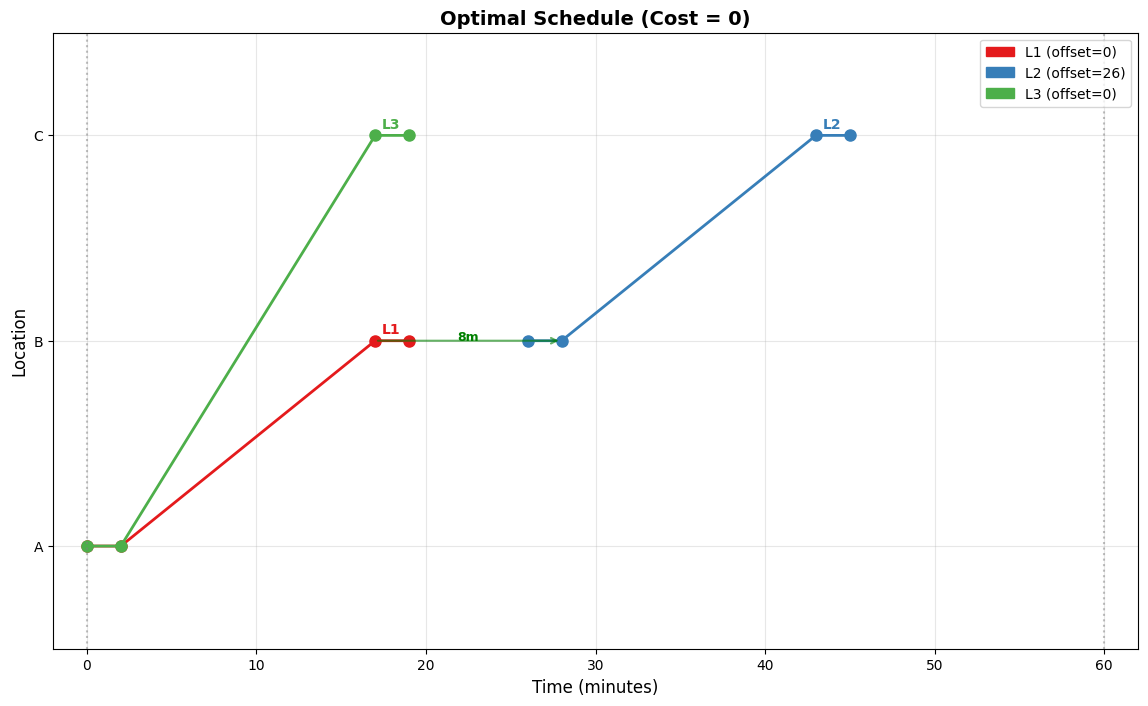

In [6]:
# Visualize optimal schedule
plotter = NetworkPlotter(network=network, transfers=transfers)

fig, ax = plotter.plot_schedule(
    optimal_schedule,
    title="Optimal Schedule (Cost = 0)"
)
plt.show()

---
## 3. MCMC Configuration

Set up the MCMC sampler parameters:

In [7]:
# MCMC Parameters
SEED = 42           # Random seed for reproducibility
N_STEPS = 500       # Number of MCMC steps (small for visualization)
BETA = 1.0          # Inverse temperature (1.0 = standard)
SIGMA = 5.0         # Standard deviation for line shifts

print("MCMC Configuration:")
print(f"  - Random seed: {SEED}")
print(f"  - Number of steps: {N_STEPS}")
print(f"  - Beta (inverse temperature): {BETA}")
print(f"  - Sigma (shift std): {SIGMA} minutes")
print(f"\nProposal: SingleLineShift")
print(f"  - Selects one line uniformly at random")
print(f"  - Shifts offset by N(0, {SIGMA}²)")
print(f"  - Symmetric proposal → Hastings ratio = 1")

MCMC Configuration:
  - Random seed: 42
  - Number of steps: 500
  - Beta (inverse temperature): 1.0
  - Sigma (shift std): 5.0 minutes

Proposal: SingleLineShift
  - Selects one line uniformly at random
  - Shifts offset by N(0, 5.0²)
  - Symmetric proposal → Hastings ratio = 1


---
## 4. Precompute MCMC History

Run the MCMC algorithm and record every step for later visualization:

In [8]:
# Create random generator
rng = np.random.default_rng(SEED)

# Create proposal
proposal = SingleLineShift(sigma=SIGMA, rng=rng)

# Create recorder (records full history)
recorder = MCMCRecorder(
    network=network,
    cost_fn=cost_fn,
    proposals=[proposal],
    beta=BETA,
    rng=rng,
)

# Initialize with random schedule
initial_schedule = Schedule.random(network, rng)
initial_cost = cost_fn(initial_schedule, network)

print(f"Initial random schedule: {initial_schedule.offsets}")
print(f"Initial cost: {initial_cost:.2f}")

recorder.initialize(
    schedule=initial_schedule,
    optimal_schedule=optimal_offsets,
    optimal_cost=optimal_cost,
)

Initial random schedule: {'L1': 5, 'L2': 46, 'L3': 39}
Initial cost: 112.50


In [9]:
%%time
# Run MCMC and record history
print(f"Running {N_STEPS} MCMC steps...")
history = recorder.run(n_steps=N_STEPS, log_every=100)
print(f"\nDone! Recorded {len(history)} steps.")

Running 500 MCMC steps...

Done! Recorded 500 steps.
CPU times: total: 125 ms
Wall time: 153 ms


In [10]:
# Quick summary
final_summary = history.summary_at_step(len(history) - 1)
best_schedule, best_cost = history.get_best_up_to(len(history) - 1)

print("MCMC Summary:")
print(f"  - Final cost: {final_summary['cost']:.4f}")
print(f"  - Best cost: {best_cost:.4f}")
print(f"  - Acceptance rate: {final_summary['acceptance_rate']:.3f}")
print(f"  - Best schedule: {best_schedule}")
print(f"  - Optimal schedule: {optimal_offsets}")
print(f"\nConverged: {'YES' if best_cost < 0.01 else 'NO'}")

MCMC Summary:
  - Final cost: 0.0000
  - Best cost: 0.0000
  - Acceptance rate: 0.460
  - Best schedule: {'L1': 10, 'L2': 36, 'L3': 44}
  - Optimal schedule: {'L1': 0, 'L2': 26, 'L3': 0}

Converged: YES


---
## 5. Interactive Step-by-Step Visualization

Use the slider and buttons to step through the MCMC history:
- **Slider**: Jump to any step
- **◀ ▶**: Step backward/forward
- **⏮ ⏭**: Jump to first/last step
- **▶ Play**: Auto-play animation

In [1]:
# Create and display interactive player
player = create_mcmc_player(
    history=history,
    network=network,
    transfers=transfers,
    cost_fn=cost_fn,
)

player.display()

NameError: name 'create_mcmc_player' is not defined

---
## 6. Results Analysis

In [2]:
# Plot cost evolution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

costs = history.get_costs()

# Cost trace
ax = axes[0]
ax.plot(costs, 'b-', alpha=0.7, linewidth=1)
best_costs = []
current_best = float('inf')
for c in costs:
    current_best = min(current_best, c)
    best_costs.append(current_best)
ax.plot(best_costs, 'g-', linewidth=2, label='Best')
ax.axhline(y=optimal_cost, color='r', linestyle='--', label='Optimal')
ax.set_xlabel('Step')
ax.set_ylabel('Cost')
ax.set_title('Cost Evolution')
ax.legend()
ax.grid(True, alpha=0.3)

# Cost histogram
ax = axes[1]
ax.hist(costs, bins=50, edgecolor='black', alpha=0.7)
ax.axvline(x=optimal_cost, color='r', linestyle='--', label='Optimal')
ax.set_xlabel('Cost')
ax.set_ylabel('Frequency')
ax.set_title('Cost Distribution')
ax.legend()

# Acceptance rate
ax = axes[2]
acceptance_rates = [history.get_acceptance_rate_up_to(i) for i in range(len(history))]
ax.plot(acceptance_rates, 'b-', linewidth=2)
ax.axhline(y=0.234, color='r', linestyle='--', label='Optimal 1D (0.234)')
ax.axhline(y=0.44, color='orange', linestyle='--', label='High-dim (0.44)')
ax.set_xlabel('Step')
ax.set_ylabel('Acceptance Rate')
ax.set_title('Cumulative Acceptance Rate')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
# Visualize cost landscape for L2
fig, ax = plotter.plot_cost_landscape(
    schedule=Schedule(offsets={"L1": 0, "L2": 0, "L3": 0}, period=60),
    line_id="L2",
    cost_fn=cost_fn,
)
plt.show()

In [ ]:
# Compare initial, final, and optimal schedules
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Initial
init_sched = Schedule(offsets=history.initial_schedule, period=network.period)
init_cost = cost_fn(init_sched, network)
plotter.plot_schedule(init_sched, ax=axes[0], title=f"Initial (Cost={init_cost:.2f})")

# Best found
best_sched = Schedule(offsets=best_schedule, period=network.period)
plotter.plot_schedule(best_sched, ax=axes[1], title=f"Best Found (Cost={best_cost:.2f})")

# Optimal
plotter.plot_schedule(optimal_schedule, ax=axes[2], title=f"Optimal (Cost={optimal_cost:.2f})")

plt.tight_layout()
plt.show()

---
## Summary

This PoC demonstrates that:
1. The MCMC algorithm successfully explores the schedule space
2. With appropriate parameters, it converges to the optimal solution
3. The acceptance rate stabilizes around the expected range

Next steps (Phase 2+):
- Test on PESPlib benchmark instances
- Implement advanced proposals (ComponentMove, SmartRepair)
- Add Parallel Tempering for better exploration